# Inverse Problems

**Seong Cho** · ACME Volume 4, Lab 19

**Lab objective:** Discuss well posed and ill posed problems, then solve a parameter estimation problem: recover the density $a(x)$ of a rod from its steady-state heat distribution, and show that this inverse problem is ill posed.

<sub>Lab specification from the *Volume 4* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from scipy.integrate import quad

## Well posed and ill posed problems

Following Jacques Hadamard, a mathematical problem is *well posed* if

1. a solution exists,
2. that solution is unique, and
3. the solution is continuously dependent on the data in the problem.

Otherwise it is *ill posed*. A well posed problem in which small changes in the data give large changes in the solution is *ill conditioned* (it has a large condition number).

Differentiation is ill posed: if $\tilde{u}(t) = u(t) + \varepsilon\sin(\varepsilon^{-2}t)$ for small $\varepsilon > 0$, then $\|u - \tilde{u}\|_\infty = \varepsilon$ while $\|u' - \tilde{u}'\|_\infty = \varepsilon^{-1}$. So is the backwards heat equation with zero Dirichlet conditions,

$$\begin{aligned} u_t &= -u_{xx}, & (x, t) &\in (0, L) \times (0, \infty), \\ u(0, t) &= u(L, t) = 0, & t &\in (0, \infty), \\ u(x, 0) &= f(x), & x &\in (0, L): \end{aligned} \tag{19.1}$$

the initial data $f(x) = \frac{1}{n}\sin(\frac{n\pi x}{L})$ gives the unique solution $u(x, t) = \frac{1}{n}\sin(\frac{n\pi x}{L})\exp((\frac{n\pi}{L})^2t)$, so as $n \to \infty$ a small difference in the initial data makes an arbitrarily large difference in the solution on $[0, T]$.

## Inverse Problems

Inverse problems come in pairs, such as differentiation and integration; the easier one (here integration) is the *direct problem*, usually studied first historically. Given a physical system and initial data (the "cause"), the direct problem predicts the future state (the "effect"); an inverse problem turns this around, for example asking what the state was at $t = 0$ given the state at time $T$, or determining a model that describes how the system evolves.

## Another look at heat flow through a rod

Consider the ODE with natural boundary conditions

$$\begin{cases} -(au')' = f, & x \in (0, 1), \\ a(0)u'(0) = c_0, \quad a(1)u'(1) = c_1. \end{cases} \tag{19.2}$$

It can describe heat flowing through a rod: the boundary conditions specify the heat flux through the ends, $f(x)$ the external heat sources and $a(x)$ the density of the rod. The direct problem solves for $u(x)$ given $a$ and $f$; here $f$ is given and $u(x)$ is measured, and we want the density $a(x)$, a *parameter estimation* problem.

With $x_j = jh$, $h = 1/N$, and the tent functions $\phi_j$ of the finite element lab, look for

$$a_h = \sum_{j=0}^N \alpha_j\phi_j, \qquad \alpha_j = a(x_j). \tag{19.3}$$

Integrating (19.2) from $0$ to $x$ gives

$$u'(x) = \frac{c_0 - \int_0^x f(s)\, ds}{a(x)}, \tag{19.4}$$

so the coefficients $\alpha_j$ in (19.3) can be approximated by minimizing

$$\sum_{j=0}^N \left(\frac{c_0 - \int_0^{x_j} f(s)\, ds}{\alpha_j} - u'(x_j)\right)^2.$$

## Problem 1: Recovering the density

> **Problem 1.** Solve (19.2) for $a(x)$ using the following conditions:
>
> $c_0 = 3/8$, $c_1 = 5/4$, $u(x) = x^2 + x/2 + 5/16$, $x_j = .1j$ for $j = 0, 1, \dots, 10$, and
>
> $$f = \begin{cases} -6x^2 + 3x - 1 & x \leq 1/2, \\ -1 & 1/2 < x \leq 1, \end{cases}$$
>
> Produce the plot shown in Figure 19.2.
>
> Hint: use the `minimize` function in `scipy.optimize` and some initial guess to find the $a_j$.

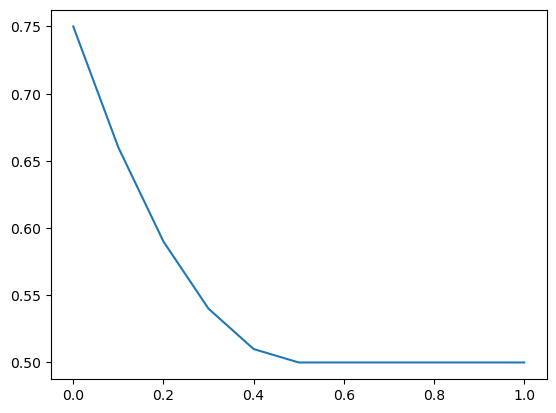

In [2]:
c0 = 3/8
c1 = 5/4
x = np.linspace(0, 1, 11)
du_func = lambda x: 2*x + 1/2
du = du_func(x)
def f_func(x):
    if x <= 1/2:
        return -6*x**2 + 3*x - 1
    else:
        return -1
If = np.array([quad(f_func, 0, xj)[0] for xj in x])

def F(a):
    return np.sum(((c0 - If)/a - du)**2)

guess = np.ones(len(x))*1/2
a = minimize(F, guess).x
plt.plot(x, a)
plt.show()

## Problem 2: An ill posed problem

> **Problem 2.** Find the density function $a(x)$ satisfying
>
> $$\begin{cases} -(au')' = -1, & x \in (0,1), \\ a(0)u'(0) = 1, & a(1)u'(1) = 2. \end{cases}$$
>
> where $u(x) = x + 1 + \epsilon\sin(\epsilon^{-2}x)$. Using several values of $\epsilon > 0.66049142$, plot the corresponding density $a(x)$ for $x$ in `np.linspace(0,1,11)` to demonstrate that the problem is ill-posed.

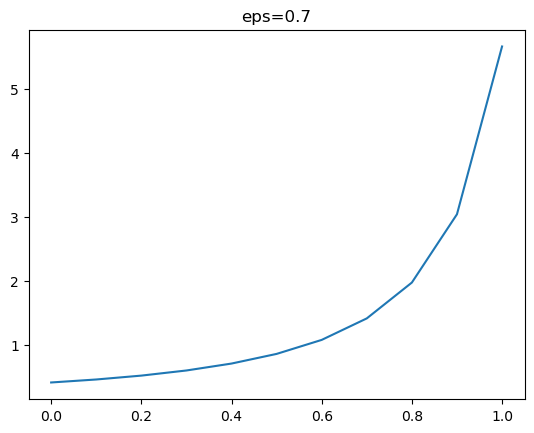

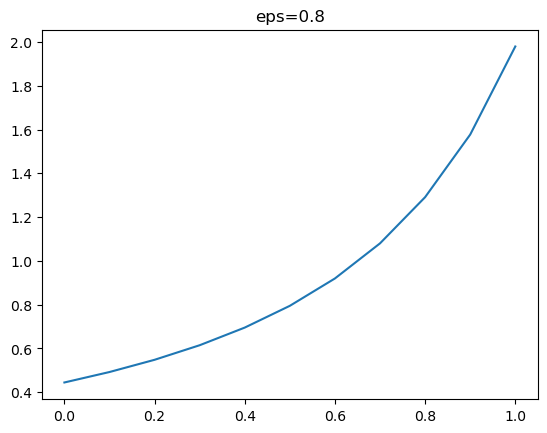

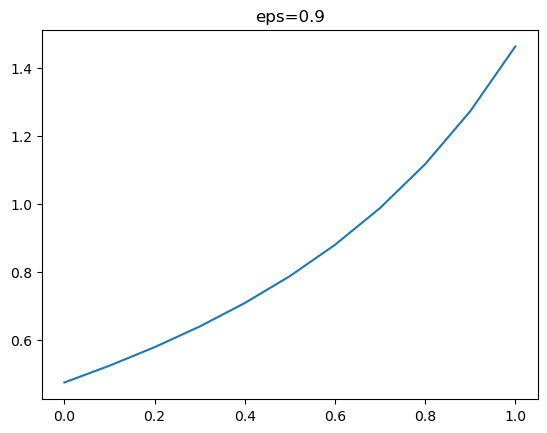

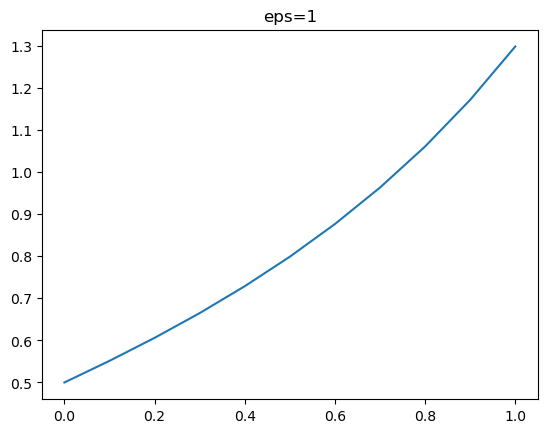

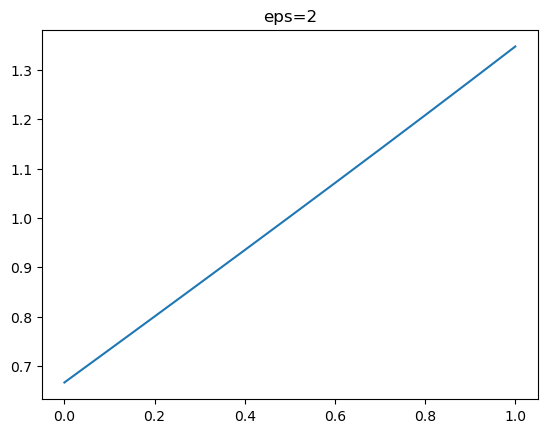

In [3]:
c0 = 1
for eps in [0.7, 0.8, 0.9, 1, 2]:
    x = np.linspace(0, 1, 11)
    du_func = lambda x: 1 + np.cos(x/eps**2)/eps
    du = du_func(x)
    If = -x
    def F(a):
        return np.sum(((c0 - If)/a - du)**2)
    guess = np.ones(len(x))*1/2
    a = minimize(F, guess).x
    plt.plot(x, a, label="eps="+str(eps))
    plt.title("eps="+str(eps))
    plt.show()